# Retail Sales, Profitability & Customer Segmentation (RFM)

**Business context:** An online retailer selling across 4 regions and 5 categories wants to know
*where money is made, where it leaks, and which customers deserve retention spend.*

**Questions answered**
1. How are sales and profit trending, and what does seasonality look like?
2. Which categories / regions / cities drive profit - and which destroy it?
3. How do discounts affect profit margin?
4. Who are our best customers (RFM segmentation) and who is about to churn?

> Data is synthetic (generated by `src/generate_data.py`) but built to mimic real retail messiness.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
inr = FuncFormatter(lambda x, _: f"₹{x/1e5:.0f}L" if abs(x) >= 1e5 else f"₹{x:,.0f}")
IMG = "../images/"


## 1. Load & inspect the raw data

In [2]:
raw = pd.read_csv("../data/retail_orders_raw.csv")
print("Shape:", raw.shape)
display(raw.head(3))
print("\nDuplicate rows:", raw.duplicated().sum())
print("Missing values:\n", raw.isna().sum()[raw.isna().sum() > 0])
print("\nCategory values:", raw.category.unique())
print("Payment values :", raw.payment_mode.unique())
print("Invalid quantity (<=0):", (raw.quantity <= 0).sum())

Shape: (13778, 17)


,order_id,order_date,ship_date,customer_id,customer_segment,region,city,category,sub_category,product_name,unit_price,quantity,discount,sales,profit,payment_mode,ship_mode
0,ORD-103220,01-01-2025,07-01-2025,C01261,Home Office,West,Mumbai,Electronics,Speakers,Speakers Model 4,10650.0,2,0.0,21300.0,4990.71,UPI,Standard
1,ORD-107337,12-06-2025,16-06-2025,C02892,Corporate,North,Chandigarh,Clothing,Women's Wear,Women's Wear Model 2,3120.0,1,0.0,3120.0,1360.43,Credit Card,Standard
2,ORD-104187,09-07-2025,11-07-2025,C01658,Consumer,North,Chandigarh,Clothing,Men's Wear,Men's Wear Model 4,1970.0,1,0.0,1970.0,826.81,COD,Express



Duplicate rows: 70
Missing values:
 city    165
dtype: int64

Category values: <StringArray>
['Electronics',    'Clothing',     'Grocery',      'Beauty',      'BEAUTY',
   'Furniture',   'FURNITURE',    'CLOTHING', 'ELECTRONICS',     'GROCERY']
Length: 10, dtype: str
Payment values : <StringArray>
['UPI', 'Credit Card', 'COD', 'Debit Card', 'Net Banking', ' upi ']
Length: 6, dtype: str
Invalid quantity (<=0): 55


## 2. Data cleaning
Every fix is logged so the cleaning is auditable (interviewers love this).

| Issue found | Fix | Reason |
|---|---|---|
| Exact duplicate rows | Drop | Would double-count revenue |
| Inconsistent category casing (`ELECTRONICS`) | Title-case | Prevents split groups |
| Payment mode has stray whitespace / case | strip + upper | Prevents split groups |
| Quantity = -1 | Drop rows | Impossible value, tiny share |
| Missing city | Fill `"Unknown"` | Keep revenue, region is still known |
| Dates stored as `dd-mm-yyyy` text | Parse to datetime | Needed for time analysis |

In [3]:
df = raw.copy()
log = {"rows_raw": len(df)}
df = df.drop_duplicates();                         log["after_dedupe"] = len(df)
df["category"] = df["category"].str.strip().str.title()
df["payment_mode"] = df["payment_mode"].str.strip().str.upper()
df = df[df["quantity"] > 0];                       log["after_invalid_qty"] = len(df)
df["city"] = df["city"].fillna("Unknown")
df["order_date"] = pd.to_datetime(df["order_date"], format="%d-%m-%Y")
df["ship_date"]  = pd.to_datetime(df["ship_date"],  format="%d-%m-%Y")
assert (df.ship_date >= df.order_date).all()
assert df.isna().sum().sum() == 0
print(log, f"\n-> removed {log['rows_raw']-len(df)} rows ({(1-len(df)/log['rows_raw']):.1%})")

# feature engineering
df["year"] = df.order_date.dt.year
df["month"] = df.order_date.dt.to_period("M").dt.to_timestamp()
df["margin"] = df.profit / df.sales
df["ship_days"] = (df.ship_date - df.order_date).dt.days
df["discount_band"] = pd.cut(df.discount, [-0.01, 0, 0.1, 0.2, 0.4], labels=["0%", "1-10%", "11-20%", "21-40%"])
df.to_csv("../data/retail_orders_clean.csv", index=False)

{'rows_raw': 13778, 'after_dedupe': 13708, 'after_invalid_qty': 13653} 
-> removed 125 rows (0.9%)


## 3. Headline KPIs

In [4]:
aov = df.groupby("order_id").sales.sum().mean()
kpi = pd.DataFrame({"KPI": ["Revenue", "Profit", "Profit margin", "Orders", "Customers", "Avg order value"],
                    "Value": [f"₹{df.sales.sum()/1e5:,.1f} L", f"₹{df.profit.sum()/1e5:,.1f} L",
                              f"{df.profit.sum()/df.sales.sum():.1%}", f"{df.order_id.nunique():,}",
                              f"{df.customer_id.nunique():,}", f"₹{aov:,.0f}"]}).set_index("KPI")
kpi

,Value
KPI,
Revenue,₹644.5 L
Profit,₹87.3 L
Profit margin,13.5%
Orders,"7,602"
Customers,"2,996"
Avg order value,"₹8,477"


## 4. Sales trend & seasonality

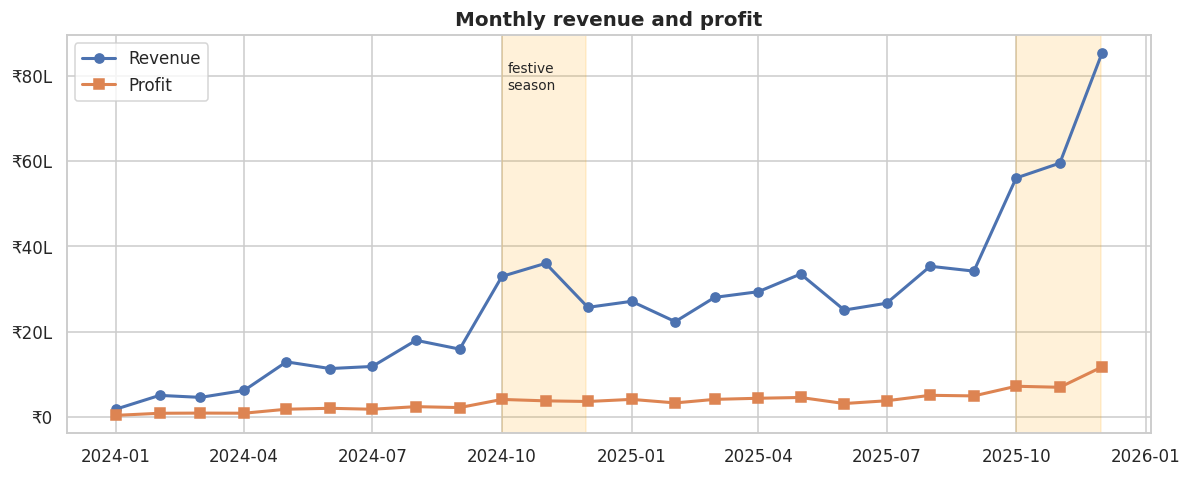

Revenue grew 154% YoY - note this is largely customer-base growth (customers keep joining), not just higher spend per customer.


In [5]:
m = df.groupby("month").agg(sales=("sales", "sum"), profit=("profit", "sum"))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(m.index, m.sales, marker="o", label="Revenue", lw=2)
ax.plot(m.index, m.profit, marker="s", label="Profit", lw=2)
ax.yaxis.set_major_formatter(inr); ax.set_title("Monthly revenue and profit"); ax.legend()
for d in pd.to_datetime(["2024-10-01", "2025-10-01"]):
    ax.axvspan(d, d + pd.offsets.MonthEnd(2), color="orange", alpha=.15)
ax.text(pd.Timestamp("2024-10-05"), m.sales.max()*.9, "festive\nseason", fontsize=9)
plt.tight_layout(); plt.savefig(IMG + "01_monthly_trend.png"); plt.show()
yoy = df.groupby("year").sales.sum()
print(f"Revenue grew {yoy[2025]/yoy[2024]-1:.0%} YoY - note this is largely customer-base growth (customers keep joining), not just higher spend per customer.")

**Reading:** revenue climbs steadily and spikes in **Oct-Dec** (festive season + year-end sales). Planning inventory,
ad budget and delivery capacity ahead of Q4 is the obvious action.

## 5. Where is the profit? Category and region

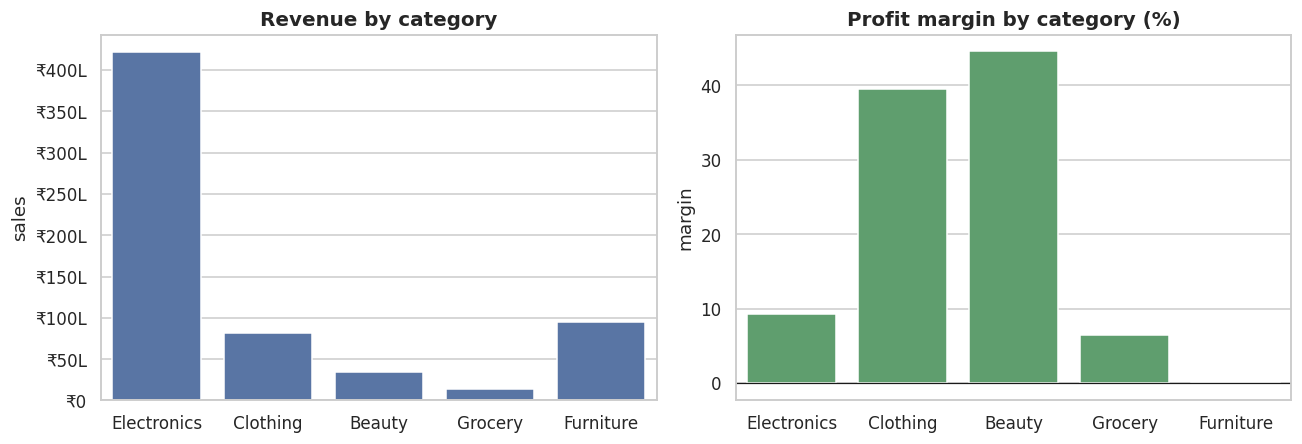

,sales,profit,margin
category,,,
Electronics,42140318.0,3927145.0,9.3%
Clothing,8104480.0,3196704.0,39.4%
Beauty,3430772.0,1528270.0,44.5%
Grocery,1333127.0,86420.0,6.5%
Furniture,9436641.0,-10006.0,-0.1%


In [6]:
cat = df.groupby("category").agg(sales=("sales", "sum"), profit=("profit", "sum"))
cat["margin"] = cat.profit / cat.sales
cat = cat.sort_values("profit", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=cat.index, y=cat.sales, ax=ax[0], color="#4c72b0"); ax[0].yaxis.set_major_formatter(inr); ax[0].set_title("Revenue by category")
sns.barplot(x=cat.index, y=cat.margin*100, hue=cat.index, legend=False, ax=ax[1], palette=["#c44e52" if v < 5 else "#55a868" for v in cat.margin*100])
ax[1].set_title("Profit margin by category (%)"); ax[1].axhline(0, color="k", lw=.8)
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.savefig(IMG + "02_category_revenue_margin.png"); plt.show()
cat.assign(margin=cat.margin.map("{:.1%}".format)).round(0)

**Reading:** Electronics is ~65% of revenue but has a thin margin. **Furniture earns roughly zero profit** and Grocery is barely above it.
Beauty and Clothing are small but extremely profitable - the opposite of where most revenue sits.

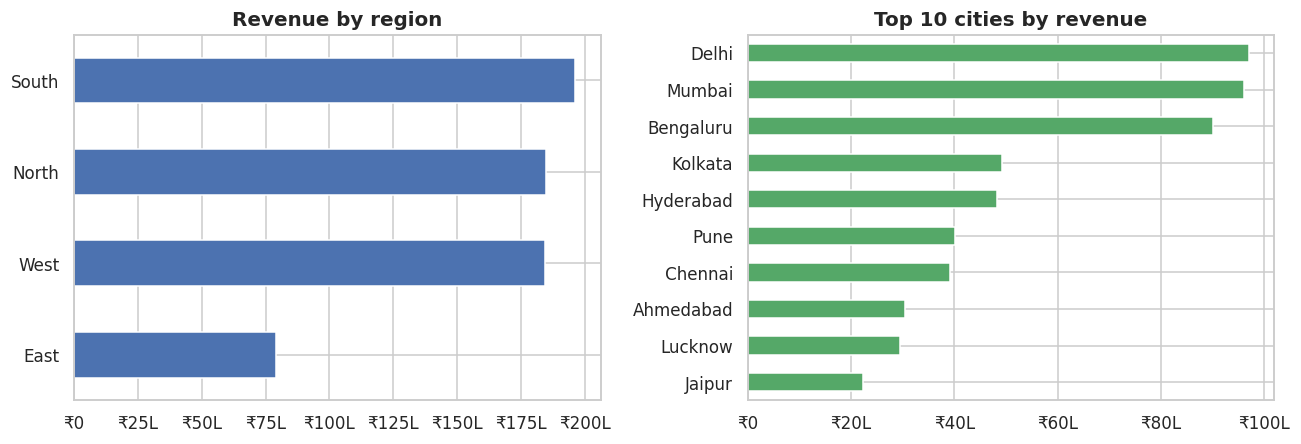

,sales,profit,margin
region,,,
East,7905821.5,968734.91,12.3%
North,18471838.0,2555539.34,13.8%
South,19629649.5,2569292.21,13.1%
West,18438029.5,2634967.11,14.3%


In [7]:
reg = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum")); reg["margin"] = reg.profit / reg.sales
city = df[df.city != "Unknown"].groupby("city").agg(sales=("sales", "sum"), profit=("profit", "sum")).sort_values("sales", ascending=False).head(10)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
reg.sales.sort_values().plot.barh(ax=ax[0], color="#4c72b0"); ax[0].xaxis.set_major_formatter(inr); ax[0].set_title("Revenue by region")
city.sales.sort_values().plot.barh(ax=ax[1], color="#55a868"); ax[1].xaxis.set_major_formatter(inr); ax[1].set_title("Top 10 cities by revenue")
for a in ax: a.set_ylabel("")
plt.tight_layout(); plt.savefig(IMG + "03_region_city.png"); plt.show()
reg.assign(margin=reg.margin.map("{:.1%}".format))

## 6. The discount problem (key insight)

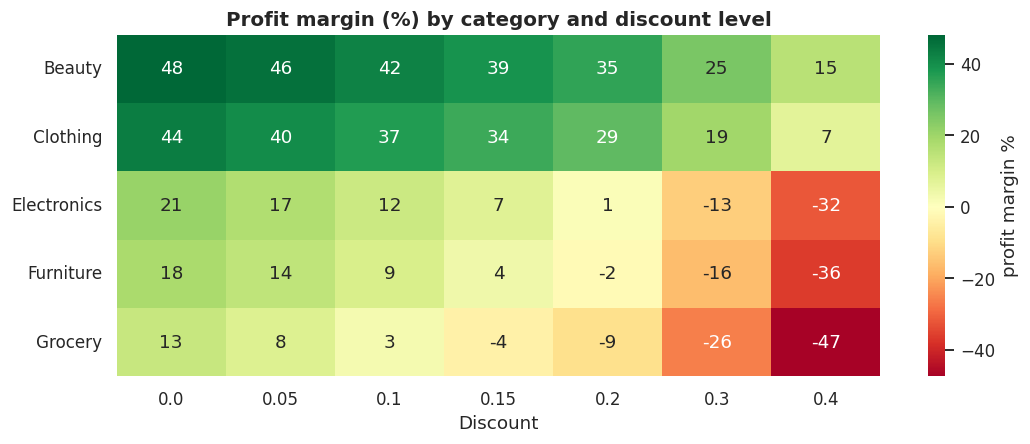

Loss-making line items: 17.4% of all lines
Total losses on those lines: ₹18.1 L
Share of those losses that came with discount >= 20%: 99%
Discount >=30%: 13.3% of revenue but profit = ₹-16.2 L


In [8]:
heat = df.pivot_table(index="category", columns="discount", values="profit", aggfunc="sum") / \
       df.pivot_table(index="category", columns="discount", values="sales", aggfunc="sum")
plt.figure(figsize=(10, 4.2))
sns.heatmap(heat*100, annot=True, fmt=".0f", cmap="RdYlGn", center=0, cbar_kws={"label": "profit margin %"})
plt.title("Profit margin (%) by category and discount level"); plt.xlabel("Discount"); plt.ylabel("")
plt.tight_layout(); plt.savefig(IMG + "04_discount_margin_heatmap.png"); plt.show()

loss = df[df.profit < 0]
print(f"Loss-making line items: {len(loss)/len(df):.1%} of all lines")
print(f"Total losses on those lines: ₹{abs(loss.profit.sum())/1e5:,.1f} L")
print(f"Share of those losses that came with discount >= 20%: {(loss[loss.discount>=.2].profit.sum()/loss.profit.sum()):.0%}")
hi = df[df.discount >= .3]
print(f"Discount >=30%: {hi.sales.sum()/df.sales.sum():.1%} of revenue but profit = ₹{hi.profit.sum()/1e5:,.1f} L")

**Reading:** discounting of **20% or more** wipes out margin in Electronics, Furniture and Grocery; at 30-40% nearly all
lines in Electronics, Furniture and Grocery lose money (Beauty and Clothing stay profitable even at 40%). A simple policy - *cap discounts at 10-15% for Electronics, Furniture and Grocery* - removes the bulk of the loss
without touching the high-margin categories.

## 7. Customer segmentation with RFM

**RFM** scores each customer on **R**ecency (days since last order), **F**requency (number of orders) and
**M**onetary value (total spend). Each is cut into 1-5 scores; combinations map to actionable segments.

,customers,avg_recency,avg_orders,revenue,pct_customers,pct_revenue
segment,,,,,,
Champions,678,29.08,4.77,27794285.0,23%,43%
Loyal,633,75.60,2.83,14753566.0,21%,23%
Cant Lose Them,248,259.77,3.52,7907360.5,8%,12%
Hibernating,711,358.75,1.02,6208794.5,24%,10%
At Risk,238,312.26,2.00,3761721.5,8%,6%
New / Promising,305,32.73,1.05,2512698.5,10%,4%
Need Attention,183,105.36,1.01,1506912.5,6%,2%


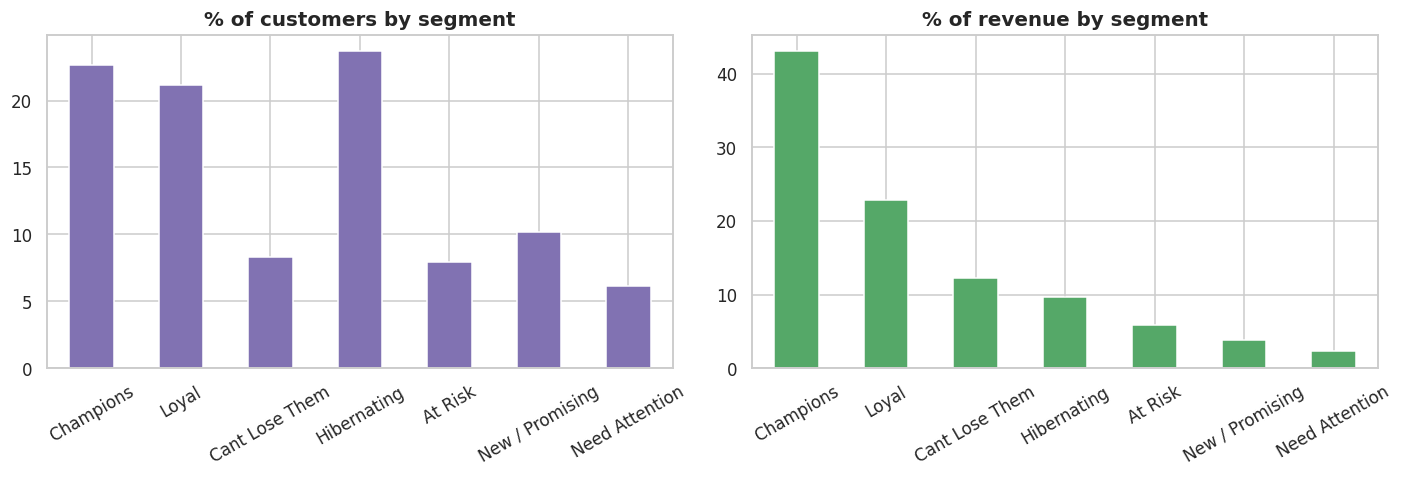

In [9]:
snapshot = df.order_date.max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_id").agg(recency=("order_date", lambda x: (snapshot - x.max()).days),
                                    frequency=("order_id", "nunique"), monetary=("sales", "sum"))
rfm["R"] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)                 # recent = high score
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / Promising"
    if r.R <= 2 and r.F >= 4: return "Cant Lose Them"
    if r.R <= 2 and r.F >= 3: return "At Risk"
    if r.R <= 2: return "Hibernating"
    return "Need Attention"
rfm["segment"] = rfm.apply(segment, axis=1)

seg = rfm.groupby("segment").agg(customers=("monetary", "size"), avg_recency=("recency", "mean"),
                                 avg_orders=("frequency", "mean"), revenue=("monetary", "sum"))
seg["pct_customers"] = seg.customers / seg.customers.sum()
seg["pct_revenue"] = seg.revenue / seg.revenue.sum()
seg = seg.sort_values("revenue", ascending=False)
display(seg.round(2).assign(pct_customers=seg.pct_customers.map("{:.0%}".format), pct_revenue=seg.pct_revenue.map("{:.0%}".format)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
seg.pct_customers.mul(100).plot.bar(ax=ax[0], color="#8172b2"); ax[0].set_title("% of customers by segment")
seg.pct_revenue.mul(100).plot.bar(ax=ax[1], color="#55a868"); ax[1].set_title("% of revenue by segment")
for a in ax: a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(IMG + "05_rfm_segments.png"); plt.show()

Pareto: top 20% of customers generate 58% of revenue
Champions: 23% of customers -> 43% of revenue
At-risk high-value groups hold ₹116.7 L of historical revenue - the win-back target list


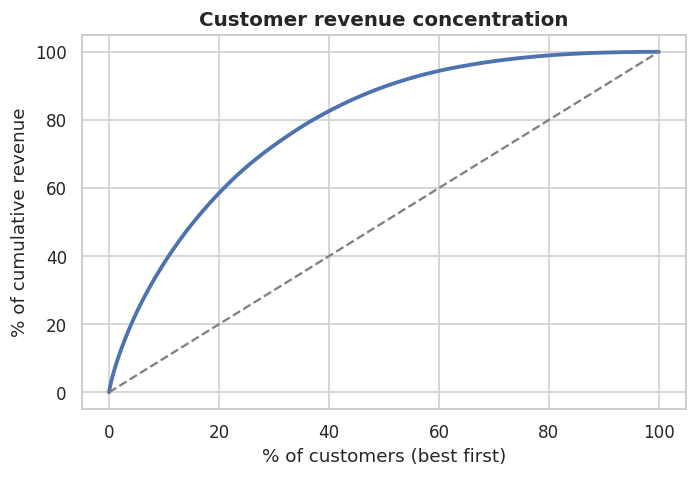

In [10]:
rfm = rfm.sort_values("monetary", ascending=False)
top20 = rfm.head(int(len(rfm)*.2)).monetary.sum() / rfm.monetary.sum()
champ = seg.loc["Champions"]
print(f"Pareto: top 20% of customers generate {top20:.0%} of revenue")
print(f"Champions: {champ.pct_customers:.0%} of customers -> {champ.pct_revenue:.0%} of revenue")
risky = seg.loc[[s for s in ['At Risk','Cant Lose Them'] if s in seg.index]]
print(f"At-risk high-value groups hold ₹{risky.revenue.sum()/1e5:,.1f} L of historical revenue - the win-back target list")

plt.figure(figsize=(6.5, 4.5))
x = np.linspace(0, 1, len(rfm)+1); y = np.r_[0, rfm.monetary.cumsum()/rfm.monetary.sum()]
plt.plot(x*100, y*100, lw=2.5); plt.plot([0, 100], [0, 100], "--", c="grey")
plt.xlabel("% of customers (best first)"); plt.ylabel("% of cumulative revenue"); plt.title("Customer revenue concentration")
plt.tight_layout(); plt.savefig(IMG + "06_pareto.png"); plt.show()
rfm.reset_index().to_csv("../data/rfm_segments.csv", index=False)

## 8. Recommendations
| # | Finding | Action | Expected impact |
|---|---|---|---|
| 1 | Discounts of 20%+ erase the margin of Electronics, Furniture and Grocery (loss-making at 30%+) | Cap discounts at 10-15% on those categories; keep deep discounts for Beauty/Clothing | Removes most loss-making lines |
| 2 | Furniture earns ~0 profit | Renegotiate supplier cost, cut deep discounts and review shipping charges (bulky items cost 4x to ship in this data) | Turns a break-even category profitable |
| 3 | Revenue spikes Oct-Dec | Pre-build inventory and ad budget from September | Fewer stock-outs at peak |
| 4 | Champions + Loyal customers drive most revenue | Early access / loyalty rewards | Protects the revenue core |
| 5 | "At Risk" and "Can't Lose Them" customers have lapsed | Targeted win-back campaign | Recovers high-value customers |

**Limitations:** synthetic data; no marketing-cost data, so profit excludes acquisition cost; RFM cut-offs are rule-based (could be replaced by k-means).